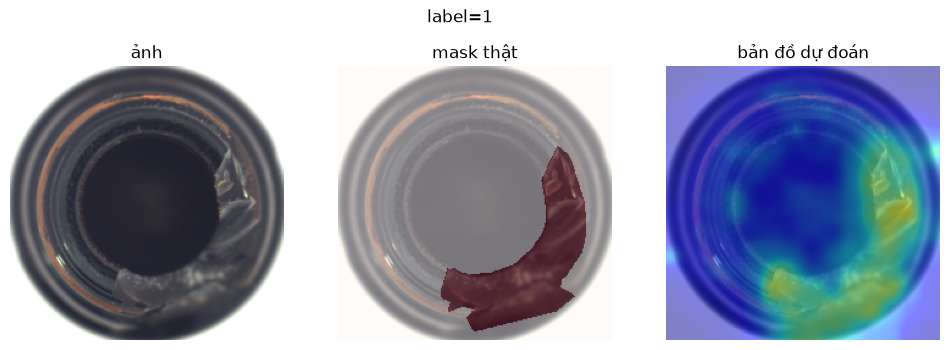

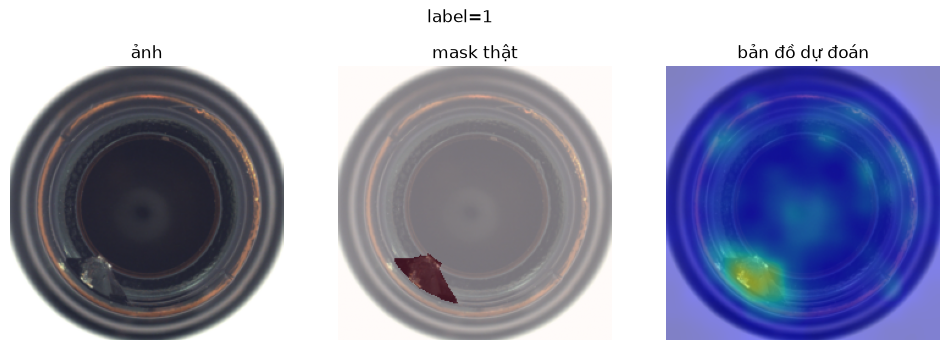

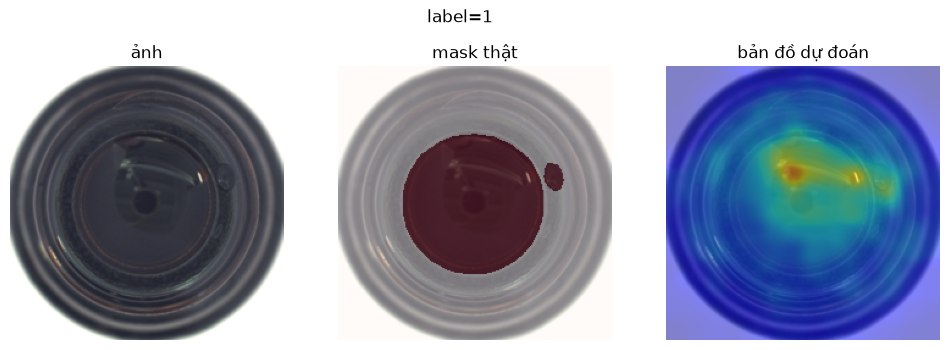

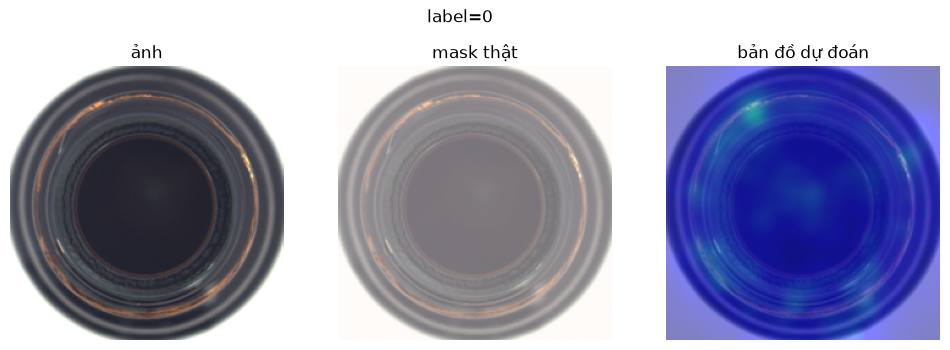

In [1]:
import sys; sys.path.append("..")
import torch
from src.data.mvtec import build_loaders
from src.models.backbone import FeatureExtractor
from src.models.padim import PaDiM
from src.evaluation.anomaly_map import upsample_and_blur, normalize
from src.utils.visualize import show_overlay

train_l, calib_l, test_l = build_loaders("../data/datasets/mvtec_ad", "bottle", batch_size=8)
model = PaDiM(FeatureExtractor(), rd=100).fit(train_l)

imgs, masks, maps, labels = [], [], [], []
for image, mask, label, path in test_l:
    imgs.append(image)
    masks.append(mask)
    maps.append(upsample_and_blur(model.score_maps(image)))
    labels.append(label)
imgs, masks, maps, labels = map(torch.cat, (imgs, masks, maps, labels))

lo, hi = maps.min(), maps.max()          # chỉ dùng để vẽ, không dùng để quyết định gì
amaps = normalize(maps, lo, hi)
for i in [0, 25, 50, 70]:                # broken_large, broken_small, contamination, good
    show_overlay(imgs[i], masks[i, 0], amaps[i], title=f"label={labels[i].item()}")